# Performance Comparison: Polars vs Pandas

## Benchmark Completo e Sistematico

Questo notebook testa le performance di **Polars vs Pandas** su:
- **Test I/O**: CSV, Parquet (diversi dataset)
- **Operazioni Base**: SELECT, FILTER, SORT, GROUP BY (su tutti i dataset)
- **Aggregazioni Complesse**: Window functions, aggregazioni multi-livello
- **JOIN Operations**: Inner, Left join su dataset di diverse dimensioni
- **Stress Test**: Memoria e performance su dataset molto grandi
- **Analisi Completa**: Visualizzazioni e report dettagliato


In [8]:
# Setup e Import
import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import psutil
import gc
import warnings
warnings.filterwarnings('ignore')

# Configurazione matplotlib
plt.style.use('default')
plt.rcParams['figure.figsize'] = (12, 8)

print("Setup completato!")
print(f"Pandas version: {pd.__version__}")
print(f"Polars version: {pl.__version__}")
print(f"Numpy version: {np.__version__}")


Setup completato!
Pandas version: 2.3.1
Polars version: 1.32.2
Numpy version: 2.2.6


In [9]:
# Funzioni di Benchmarking

class BenchmarkResult:
    def __init__(self, operation, library, time_taken, memory_used, rows, dataset_size, notes=""):
        self.operation = operation
        self.library = library
        self.time_taken = time_taken
        self.memory_used = memory_used
        self.rows = rows
        self.dataset_size = dataset_size
        self.notes = notes

def get_memory_usage():
    """Restituisce l'uso di memoria corrente in MB"""
    process = psutil.Process()
    return process.memory_info().rss / 1024 / 1024

def benchmark_operation(func, *args, **kwargs):
    """Esegue il benchmark di un'operazione misurando tempo e memoria"""
    gc.collect() # Pulizia garbage collector
    
    memory_before = get_memory_usage()
    start_time = time.time()
    
    result = func(*args, **kwargs)
    
    end_time = time.time()
    memory_after = get_memory_usage()
    
    time_taken = end_time - start_time
    memory_used = memory_after - memory_before
    
    return result, time_taken, memory_used

# Lista per raccogliere i risultati
benchmark_results = []

def add_benchmark_result(operation, library, time_taken, memory_used, rows, dataset_size, notes=""):
    """Aggiunge un risultato di benchmark alla lista"""
    result = BenchmarkResult(operation, library, time_taken, memory_used, rows, dataset_size, notes)
    benchmark_results.append(result)
    print(f" {library} - {operation} ({dataset_size}): {time_taken:.3f}s, {memory_used:.2f}MB")

print("Funzioni di benchmark caricate!")


Funzioni di benchmark caricate!


In [10]:
# Generazione Dataset di Test Completi

def generate_test_data(n_rows, complexity='medium'):
    """Genera dataset di test con diversi livelli di complessità"""
    np.random.seed(42) # Per risultati riproducibili
    
    # Genera date randomiche per evitare overflow
    start_date = pd.Timestamp('2020-01-01')
    end_date = pd.Timestamp('2023-01-01')
    date_range_days = (end_date - start_date).days
    random_days = np.random.randint(0, date_range_days, n_rows)
    random_dates = [start_date + pd.Timedelta(days=int(days)) for days in random_days]
    
    data = {
        'id': range(n_rows),
        'numeric_col1': np.random.randn(n_rows),
        'numeric_col2': np.random.uniform(0, 1000, n_rows),
        'category': np.random.choice(['A', 'B', 'C', 'D', 'E'], n_rows),
        'date': random_dates,
        'boolean': np.random.choice([True, False], n_rows),
    }
    
    if complexity in ['medium', 'high']:
        data.update({
            'text_col': [f'text_{i%1000}' for i in range(n_rows)],
            'numeric_col3': np.random.exponential(2, n_rows),
            'category2': np.random.choice([f'Cat_{i}' for i in range(50)], n_rows),
        })
    
    if complexity == 'high':
        for i in range(5):
            data[f'extra_numeric_{i}'] = np.random.randn(n_rows)
            data[f'extra_category_{i}'] = np.random.choice([f'X{i}_{j}' for j in range(10)], n_rows)
    
    return data

# Creazione dataset di TUTTE le dimensioni per test completi
dataset_sizes = {
    'piccolo': 10_000,
    'medio': 100_000,
    'grande': 1_000_000,
    'molto_grande': 10_000_000 # Dimensione gestibile
}

print("Creazione dataset di TUTTE le dimensioni...")
test_datasets = {}
dataset_info = {}

for size_name, n_rows in dataset_sizes.items():
    print(f"Generando dataset {size_name}: {n_rows:,} righe...")
    try:
        data = generate_test_data(n_rows, 'medium')
        test_datasets[size_name] = data
        dataset_info[size_name] = {
            'rows': n_rows,
            'cols': len(data),
            'memory_est_mb': (n_rows * len(data) * 8) / (1024 * 1024) # Stima approssimativa
        }
        print(f"Dataset {size_name} creato: {len(data)} colonne, ~{dataset_info[size_name]['memory_est_mb']:.1f}MB")
    except Exception as e:
        print(f"Errore creando dataset {size_name}: {e}")

print(f"\nDataset pronti: {list(test_datasets.keys())}")
print("Pronti per test completi su TUTTI i dataset!")


Creazione dataset di TUTTE le dimensioni...
Generando dataset piccolo: 10,000 righe...
Dataset piccolo creato: 9 colonne, ~0.7MB
Generando dataset medio: 100,000 righe...
Dataset medio creato: 9 colonne, ~6.9MB
Generando dataset grande: 1,000,000 righe...
Dataset grande creato: 9 colonne, ~68.7MB
Generando dataset molto_grande: 10,000,000 righe...
Dataset molto_grande creato: 9 colonne, ~686.6MB

Dataset pronti: ['piccolo', 'medio', 'grande', 'molto_grande']
Pronti per test completi su TUTTI i dataset!


In [11]:
# TEST 1: Operazioni I/O Complete (CSV & Parquet)
print("TEST 1: Operazioni I/O su Diversi Dataset")
print("="*60)

# Test I/O su dataset medio e grande per vedere le differenze
test_sizes_io = ['medio', 'grande']

for size_name in test_sizes_io:
    if size_name in test_datasets:
        print(f"\nTest I/O su dataset {size_name}: {dataset_info[size_name]['rows']:,} righe")
        
        # Crea DataFrames
        test_data = test_datasets[size_name]
        df_pandas = pd.DataFrame(test_data)
        df_polars = pl.DataFrame(test_data)
        
        # TEST CSV WRITE
        print(f"\nTest Scrittura CSV ({size_name}):")
        
        def write_csv_pandas():
            df_pandas.to_csv(f'/tmp/test_pandas_{size_name}.csv', index=False)
        
        def write_csv_polars():
            df_polars.write_csv(f'/tmp/test_polars_{size_name}.csv')
        
        try:
            _, time_pandas, mem_pandas = benchmark_operation(write_csv_pandas)
            _, time_polars, mem_polars = benchmark_operation(write_csv_polars)
            
            add_benchmark_result("CSV Write", "Pandas", time_pandas, mem_pandas, len(df_pandas), size_name)
            add_benchmark_result("CSV Write", "Polars", time_polars, mem_polars, len(df_polars), size_name)
        except Exception as e:
            print(f"Errore CSV Write {size_name}: {e}")
        
        # TEST CSV READ
        print(f"\nTest Lettura CSV ({size_name}):")
        
        def read_csv_pandas():
            return pd.read_csv(f'/tmp/test_pandas_{size_name}.csv')
        
        def read_csv_polars():
            return pl.read_csv(f'/tmp/test_polars_{size_name}.csv')
        
        try:
            _, time_pandas, mem_pandas = benchmark_operation(read_csv_pandas)
            _, time_polars, mem_polars = benchmark_operation(read_csv_polars)
            
            add_benchmark_result("CSV Read", "Pandas", time_pandas, mem_pandas, len(df_pandas), size_name)
            add_benchmark_result("CSV Read", "Polars", time_polars, mem_polars, len(df_polars), size_name)
        except Exception as e:
            print(f"Errore CSV Read {size_name}: {e}")
        
        # TEST PARQUET WRITE
        print(f"\nTest Scrittura Parquet ({size_name}):")
        
        def write_parquet_pandas():
            df_pandas.to_parquet(f'/tmp/test_pandas_{size_name}.parquet', index=False)
        
        def write_parquet_polars():
            df_polars.write_parquet(f'/tmp/test_polars_{size_name}.parquet')
        
        try:
            _, time_pandas, mem_pandas = benchmark_operation(write_parquet_pandas)
            _, time_polars, mem_polars = benchmark_operation(write_parquet_polars)
            
            add_benchmark_result("Parquet Write", "Pandas", time_pandas, mem_pandas, len(df_pandas), size_name)
            add_benchmark_result("Parquet Write", "Polars", time_polars, mem_polars, len(df_polars), size_name)
        except Exception as e:
            print(f"Errore Parquet Write {size_name}: {e}")
        
        # TEST PARQUET READ
        print(f"\nTest Lettura Parquet ({size_name}):")
        
        def read_parquet_pandas():
            return pd.read_parquet(f'/tmp/test_pandas_{size_name}.parquet')
        
        def read_parquet_polars():
            return pl.read_parquet(f'/tmp/test_polars_{size_name}.parquet')
        
        try:
            _, time_pandas, mem_pandas = benchmark_operation(read_parquet_pandas)
            _, time_polars, mem_polars = benchmark_operation(read_parquet_polars)
            
            add_benchmark_result("Parquet Read", "Pandas", time_pandas, mem_pandas, len(df_pandas), size_name)
            add_benchmark_result("Parquet Read", "Polars", time_polars, mem_polars, len(df_polars), size_name)
        except Exception as e:
            print(f"Errore Parquet Read {size_name}: {e}")
        
        # Cleanup
        del df_pandas, df_polars
        gc.collect()
        
    else:
        print(f"Dataset {size_name} non disponibile")

print("\nTest I/O completati su tutti i dataset!")


TEST 1: Operazioni I/O su Diversi Dataset

Test I/O su dataset medio: 100,000 righe

Test Scrittura CSV (medio):
Pandas - CSV Write (medio): 0.405s, 8.17MB
Polars - CSV Write (medio): 0.046s, 4.94MB

Test Lettura CSV (medio):
Pandas - CSV Read (medio): 0.074s, 29.70MB
Polars - CSV Read (medio): 0.019s, 15.16MB

Test Scrittura Parquet (medio):
Errore Parquet Write medio: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
- Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
- Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.

Test Lettura Parquet (medio):
Errore Parquet Read medio: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet i

In [12]:
# TEST 2: Operazioni Base su TUTTI i Dataset
print("\nTEST 2: Operazioni Base - Scalabilità")
print("="*60)

# Test su TUTTI i dataset per vedere la scalabilità
all_sizes = ['piccolo', 'medio', 'grande'] # Escludiamo molto_grande per ora

for size_name in all_sizes:
    if size_name in test_datasets:
        print(f"\nTest Operazioni Base su dataset {size_name.upper()}: {dataset_info[size_name]['rows']:,} righe")
        
        # Crea DataFrames
        test_data = test_datasets[size_name]
        df_pandas = pd.DataFrame(test_data)
        df_polars = pl.DataFrame(test_data)
        
        # TEST SELECT
        print(f"\nSELECT ({size_name}):")
        
        def select_pandas():
            return df_pandas[['id', 'numeric_col1', 'category']].copy()
        
        def select_polars():
            return df_polars.select(['id', 'numeric_col1', 'category'])
        
        try:
            _, time_pandas, mem_pandas = benchmark_operation(select_pandas)
            _, time_polars, mem_polars = benchmark_operation(select_polars)
            
            add_benchmark_result("SELECT", "Pandas", time_pandas, mem_pandas, len(df_pandas), size_name)
            add_benchmark_result("SELECT", "Polars", time_polars, mem_polars, len(df_polars), size_name)
        except Exception as e:
            print(f"Errore SELECT {size_name}: {e}")
        
        # TEST FILTER
        print(f"\nFILTER ({size_name}):")
        
        def filter_pandas():
            return df_pandas[
                (df_pandas['numeric_col1'] > 0) &
                (df_pandas['category'].isin(['A', 'B']))
            ].copy()
        
        def filter_polars():
            return df_polars.filter(
                (pl.col('numeric_col1') > 0) &
                (pl.col('category').is_in(['A', 'B']))
            )
        
        try:
            _, time_pandas, mem_pandas = benchmark_operation(filter_pandas)
            _, time_polars, mem_polars = benchmark_operation(filter_polars)
            
            add_benchmark_result("FILTER", "Pandas", time_pandas, mem_pandas, len(df_pandas), size_name)
            add_benchmark_result("FILTER", "Polars", time_polars, mem_polars, len(df_polars), size_name)
        except Exception as e:
            print(f"Errore FILTER {size_name}: {e}")
        
        # TEST SORT
        print(f"\nSORT ({size_name}):")
        
        def sort_pandas():
            return df_pandas.sort_values(['numeric_col1', 'category'])
        
        def sort_polars():
            return df_polars.sort(['numeric_col1', 'category'])
        
        try:
            _, time_pandas, mem_pandas = benchmark_operation(sort_pandas)
            _, time_polars, mem_polars = benchmark_operation(sort_polars)
            
            add_benchmark_result("SORT", "Pandas", time_pandas, mem_pandas, len(df_pandas), size_name)
            add_benchmark_result("SORT", "Polars", time_polars, mem_polars, len(df_polars), size_name)
        except Exception as e:
            print(f"Errore SORT {size_name}: {e}")
        
        # TEST GROUP BY
        print(f"\nGROUP BY ({size_name}):")
        
        def groupby_pandas():
            return df_pandas.groupby('category').agg({
                'numeric_col1': ['mean', 'sum', 'count'],
                'numeric_col2': ['min', 'max']
            })
        
        def groupby_polars():
            return df_polars.group_by('category').agg([
                pl.col('numeric_col1').mean().alias('numeric_col1_mean'),
                pl.col('numeric_col1').sum().alias('numeric_col1_sum'),
                pl.col('numeric_col1').count().alias('numeric_col1_count'),
                pl.col('numeric_col2').min().alias('numeric_col2_min'),
                pl.col('numeric_col2').max().alias('numeric_col2_max')
            ])
        
        try:
            _, time_pandas, mem_pandas = benchmark_operation(groupby_pandas)
            _, time_polars, mem_polars = benchmark_operation(groupby_polars)
            
            add_benchmark_result("GROUP BY", "Pandas", time_pandas, mem_pandas, len(df_pandas), size_name)
            add_benchmark_result("GROUP BY", "Polars", time_polars, mem_polars, len(df_polars), size_name)
        except Exception as e:
            print(f"Errore GROUP BY {size_name}: {e}")
        
        # Cleanup
        del df_pandas, df_polars
        gc.collect()
        
        print(f"Operazioni base completate su dataset {size_name}")
    else:
        print(f"Dataset {size_name} non disponibile")

print("\nTest operazioni base completati su TUTTI i dataset!")



TEST 2: Operazioni Base - Scalabilità

Test Operazioni Base su dataset PICCOLO: 10,000 righe

SELECT (piccolo):
Pandas - SELECT (piccolo): 0.002s, 0.12MB
Polars - SELECT (piccolo): 0.000s, 0.00MB

FILTER (piccolo):
Pandas - FILTER (piccolo): 0.001s, 0.08MB
Polars - FILTER (piccolo): 0.001s, 0.17MB

SORT (piccolo):
Pandas - SORT (piccolo): 0.006s, 0.17MB
Polars - SORT (piccolo): 0.003s, 0.25MB

GROUP BY (piccolo):
Pandas - GROUP BY (piccolo): 0.002s, 0.12MB
Polars - GROUP BY (piccolo): 0.001s, 0.27MB
Operazioni base completate su dataset piccolo

Test Operazioni Base su dataset MEDIO: 100,000 righe

SELECT (medio):
Pandas - SELECT (medio): 0.002s, 2.33MB
Polars - SELECT (medio): 0.000s, 0.00MB

FILTER (medio):
Pandas - FILTER (medio): 0.005s, 0.00MB
Polars - FILTER (medio): 0.001s, 0.20MB

SORT (medio):
Pandas - SORT (medio): 0.039s, 0.53MB
Polars - SORT (medio): 0.005s, 0.61MB

GROUP BY (medio):
Pandas - GROUP BY (medio): 0.008s, -0.91MB
Polars - GROUP BY (medio): 0.002s, 0.27MB
Opera

In [13]:
# TEST 3: Aggregazioni Complesse e Window Functions
print("\nTEST 3: Aggregazioni Complesse")
print("="*60)

# Test su dataset grande per aggregazioni complesse
if 'grande' in test_datasets:
    print(f"\nTest Aggregazioni su dataset GRANDE: {dataset_info['grande']['rows']:,} righe")
    
    test_data_large = test_datasets['grande']
    df_pandas_large = pd.DataFrame(test_data_large)
    df_polars_large = pl.DataFrame(test_data_large)
    
    # TEST AGGREGAZIONI COMPLESSE
    print("\nTest Aggregazioni Complesse Multi-Livello:")
    
    def complex_aggregation_pandas():
        return df_pandas_large.groupby(['category', 'boolean']).agg({
            'numeric_col1': ['mean', 'std', 'min', 'max'],
            'numeric_col2': ['sum', 'median', lambda x: x.max() - x.min()], # range
            'id': 'count'
        }).round(4)
    
    def complex_aggregation_polars():
        return df_polars_large.group_by(['category', 'boolean']).agg([
            pl.col('numeric_col1').mean().alias('numeric_col1_mean'),
            pl.col('numeric_col1').std().alias('numeric_col1_std'),
            pl.col('numeric_col1').min().alias('numeric_col1_min'),
            pl.col('numeric_col1').max().alias('numeric_col1_max'),
            pl.col('numeric_col2').sum().alias('numeric_col2_sum'),
            pl.col('numeric_col2').median().alias('numeric_col2_median'),
            (pl.col('numeric_col2').max() - pl.col('numeric_col2').min()).alias('numeric_col2_range'),
            pl.col('id').count().alias('count')
        ]).round(4)
    
    try:
        _, time_pandas, mem_pandas = benchmark_operation(complex_aggregation_pandas)
        _, time_polars, mem_polars = benchmark_operation(complex_aggregation_polars)
        
        add_benchmark_result("Complex Aggregation", "Pandas", time_pandas, mem_pandas, len(df_pandas_large), "grande")
        add_benchmark_result("Complex Aggregation", "Polars", time_polars, mem_polars, len(df_polars_large), "grande")
    except Exception as e:
        print(f"Errore Complex Aggregation: {e}")
    
    # TEST WINDOW FUNCTIONS
    print("\nTest Window Functions:")
    
    def window_function_pandas():
        df_copy = df_pandas_large.copy()
        df_copy['running_sum'] = df_copy.groupby('category')['numeric_col1'].cumsum()
        df_copy['rank'] = df_copy.groupby('category')['numeric_col2'].rank(method='dense')
        df_copy['row_number'] = df_copy.groupby('category').cumcount() + 1
        return df_copy
    
    def window_function_polars():
        return df_polars_large.with_columns([
            pl.col('numeric_col1').cumsum().over('category').alias('running_sum'),
            pl.col('numeric_col2').rank(method='dense').over('category').alias('rank'),
            pl.int_range(pl.len()).over('category').alias('row_number')
        ])
    
    try:
        _, time_pandas, mem_pandas = benchmark_operation(window_function_pandas)
        _, time_polars, mem_polars = benchmark_operation(window_function_polars)
        
        add_benchmark_result("Window Functions", "Pandas", time_pandas, mem_pandas, len(df_pandas_large), "grande")
        add_benchmark_result("Window Functions", "Polars", time_polars, mem_polars, len(df_polars_large), "grande")
    except Exception as e:
        print(f"Errore Window Functions: {e}")
    
    # Cleanup
    del df_pandas_large, df_polars_large
    gc.collect()
    
    print("Test aggregazioni complesse completati!")
else:
    print("Dataset grande non disponibile per aggregazioni complesse")



TEST 3: Aggregazioni Complesse

Test Aggregazioni su dataset GRANDE: 1,000,000 righe

Test Aggregazioni Complesse Multi-Livello:
Errore Complex Aggregation: 'DataFrame'object has no attribute 'round'

Test Window Functions:
Errore Window Functions: 'Expr'object has no attribute 'cumsum'
Test aggregazioni complesse completati!


In [14]:
# TEST 4: Operazioni JOIN su Diversi Dataset
print("\nTEST 4: Operazioni JOIN")
print("="*60)

# Creare dataset secondario per i join
secondary_data = {
    'category': ['A', 'B', 'C', 'D', 'E', 'F'],
    'category_name': ['Alpha', 'Beta', 'Gamma', 'Delta', 'Epsilon', 'Zeta'],
    'multiplier': [1.1, 1.2, 1.3, 1.4, 1.5, 1.6],
    'priority': [1, 2, 3, 2, 1, 3]
}

df_secondary_pandas = pd.DataFrame(secondary_data)
df_secondary_polars = pl.DataFrame(secondary_data)

print(f"Dataset secondario: {len(df_secondary_pandas)} righe")

# Test JOIN su diversi dataset per vedere la scalabilità
join_test_sizes = ['medio', 'grande']

for size_name in join_test_sizes:
    if size_name in test_datasets:
        print(f"\nTest JOIN su dataset {size_name.upper()}: {dataset_info[size_name]['rows']:,} righe")
        
        test_data = test_datasets[size_name]
        df_pandas_main = pd.DataFrame(test_data)
        df_polars_main = pl.DataFrame(test_data)
        
        # TEST INNER JOIN
        print(f"\nInner JOIN ({size_name}):")
        
        def inner_join_pandas():
            return df_pandas_main.merge(df_secondary_pandas, on='category', how='inner')
        
        def inner_join_polars():
            return df_polars_main.join(df_secondary_polars, on='category', how='inner')
        
        try:
            _, time_pandas, mem_pandas = benchmark_operation(inner_join_pandas)
            _, time_polars, mem_polars = benchmark_operation(inner_join_polars)
            
            add_benchmark_result("Inner JOIN", "Pandas", time_pandas, mem_pandas, len(df_pandas_main), size_name)
            add_benchmark_result("Inner JOIN", "Polars", time_polars, mem_polars, len(df_polars_main), size_name)
        except Exception as e:
            print(f"Errore Inner JOIN {size_name}: {e}")
        
        # TEST LEFT JOIN
        print(f"\nLeft JOIN ({size_name}):")
        
        def left_join_pandas():
            return df_pandas_main.merge(df_secondary_pandas, on='category', how='left')
        
        def left_join_polars():
            return df_polars_main.join(df_secondary_polars, on='category', how='left')
        
        try:
            _, time_pandas, mem_pandas = benchmark_operation(left_join_pandas)
            _, time_polars, mem_polars = benchmark_operation(left_join_polars)
            
            add_benchmark_result("Left JOIN", "Pandas", time_pandas, mem_pandas, len(df_pandas_main), size_name)
            add_benchmark_result("Left JOIN", "Polars", time_polars, mem_polars, len(df_polars_main), size_name)
        except Exception as e:
            print(f"Errore Left JOIN {size_name}: {e}")
        
        # Cleanup
        del df_pandas_main, df_polars_main
        gc.collect()
        
        print(f"JOIN completati su dataset {size_name}")
    else:
        print(f"Dataset {size_name} non disponibile per JOIN")

print("\nTest JOIN completati su tutti i dataset!")



TEST 4: Operazioni JOIN
Dataset secondario: 6 righe

Test JOIN su dataset MEDIO: 100,000 righe

Inner JOIN (medio):
Pandas - Inner JOIN (medio): 0.012s, 0.69MB
Polars - Inner JOIN (medio): 0.010s, 0.77MB

Left JOIN (medio):
Pandas - Left JOIN (medio): 0.014s, 0.83MB
Polars - Left JOIN (medio): 0.004s, 0.66MB
JOIN completati su dataset medio

Test JOIN su dataset GRANDE: 1,000,000 righe

Inner JOIN (grande):
Pandas - Inner JOIN (grande): 0.102s, 10.73MB
Polars - Inner JOIN (grande): 0.025s, 114.70MB

Left JOIN (grande):
Pandas - Left JOIN (grande): 0.118s, 8.19MB
Polars - Left JOIN (grande): 0.012s, 23.20MB
JOIN completati su dataset grande

Test JOIN completati su tutti i dataset!


In [ ]:
# TEST 5: Stress Test su Dataset Molto Grande
print("\nTEST 5: Stress Test - Dataset Molto Grande")
print("="*60)

# Test su dataset molto grande per stress test
if 'molto_grande' in test_datasets:
    print(f"\nSTRESS TEST su dataset MOLTO GRANDE: {dataset_info['molto_grande']['rows']:,} righe")
    print(f"Memoria stimata: ~{dataset_info['molto_grande']['memory_est_mb']:.1f}MB")
    
    test_data_xl = test_datasets['molto_grande']
    
    # TEST CREAZIONE DATAFRAMES
    print("\nTest Creazione DataFrame Molto Grande:")
    
    def create_pandas_xl():
        return pd.DataFrame(test_data_xl)
    
    def create_polars_xl():
        return pl.DataFrame(test_data_xl)
    
    try:
        df_pandas_xl, time_pandas, mem_pandas = benchmark_operation(create_pandas_xl)
        df_polars_xl, time_polars, mem_polars = benchmark_operation(create_polars_xl)
        
        add_benchmark_result("DataFrame Creation", "Pandas", time_pandas, mem_pandas, len(df_pandas_xl), "molto_grande")
        add_benchmark_result("DataFrame Creation", "Polars", time_polars, mem_polars, len(df_polars_xl), "molto_grande")
        
        # TEST OPERAZIONE COMPLESSA SU DATASET MOLTO GRANDE
        print("\nTest Operazione Complessa (Chain) su Dataset Molto Grande:")
        
        def complex_chain_pandas():
            return (df_pandas_xl
                    .query('numeric_col1 > 0')
                    .groupby(['category', 'boolean'])
                    .agg({'numeric_col1': 'mean', 'numeric_col2': 'sum'})
                    .reset_index()
                    .sort_values('numeric_col1')
                    .head(1000))
        
        def complex_chain_polars():
            return (df_polars_xl
                    .filter(pl.col('numeric_col1') > 0)
                    .group_by(['category', 'boolean'])
                    .agg([
                        pl.col('numeric_col1').mean(),
                        pl.col('numeric_col2').sum()
                    ])
                    .sort('numeric_col1')
                    .head(1000))
        
        try:
            _, time_pandas, mem_pandas = benchmark_operation(complex_chain_pandas)
            _, time_polars, mem_polars = benchmark_operation(complex_chain_polars)
            
            add_benchmark_result("Complex Chain", "Pandas", time_pandas, mem_pandas, len(df_pandas_xl), "molto_grande")
            add_benchmark_result("Complex Chain", "Polars", time_polars, mem_polars, len(df_polars_xl), "molto_grande")
        except Exception as e:
            print(f"Errore Complex Chain: {e}")
        
        # Cleanup per liberare memoria
        del df_pandas_xl, df_polars_xl
        gc.collect()
        
        print("Stress test completato!")
        
    except Exception as e:
        print(f"Errore nella creazione DataFrame molto grande: {e}")
        print("Potrebbe essere necessario ridurre la dimensione del dataset")
else:
    print("Dataset molto grande non disponibile per stress test")



TEST 5: Stress Test - Dataset Molto Grande

STRESS TEST su dataset MOLTO GRANDE: 10,000,000 righe
Memoria stimata: ~686.6MB

Test Creazione DataFrame Molto Grande:


In [ ]:
# ANALISI COMPLETA E VISUALIZZAZIONI
print("\nANALISI COMPLETA DEI RISULTATI")
print("="*70)

if benchmark_results:
    # Conversione risultati in DataFrame per analisi
    results_data = []
    for result in benchmark_results:
        results_data.append({
            'Operation': result.operation,
            'Library': result.library,
            'Time (seconds)': result.time_taken,
            'Memory (MB)': result.memory_used,
            'Rows': result.rows,
            'Dataset_Size': result.dataset_size,
            'Notes': result.notes
        })
    
    results_df = pd.DataFrame(results_data)
    
    # Mostra tabella riassuntiva COMPLETA
    print(f"\nTABELLA RIASSUNTIVA COMPLETA ({len(benchmark_results)} test):")
    print(results_df.to_string(index=False))
    
    # Analisi per operazione
    print("\nANALISI PER OPERAZIONE:")
    for operation in results_df['Operation'].unique():
        op_data = results_df[results_df['Operation'] == operation]
        print(f"\n {operation}:")
        print(op_data[['Library', 'Time (seconds)', 'Memory (MB)', 'Dataset_Size']].to_string(index=False))
    
    # Calcola speedup per ogni combinazione operazione-dataset
    print("\nSPEEDUP DETTAGLIATO (Polars vs Pandas):")
    speedup_data = []
    
    for operation in results_df['Operation'].unique():
        for dataset in results_df['Dataset_Size'].unique():
            op_data = results_df[
                (results_df['Operation'] == operation) &
                (results_df['Dataset_Size'] == dataset)
            ]
            if len(op_data) == 2: # Abbiamo sia Pandas che Polars
                pandas_time = op_data[op_data['Library'] == 'Pandas']['Time (seconds)'].iloc[0]
                polars_time = op_data[op_data['Library'] == 'Polars']['Time (seconds)'].iloc[0]
                if polars_time > 0:
                    speedup = pandas_time / polars_time
                    speedup_data.append({
                        'Operation': operation,
                        'Dataset': dataset,
                        'Pandas_Time': pandas_time,
                        'Polars_Time': polars_time,
                        'Speedup': speedup,
                        'Winner': 'Polars' if speedup > 1 else 'Pandas'
                    })
    
    if speedup_data:
        speedup_df = pd.DataFrame(speedup_data)
        print(speedup_df.to_string(index=False))
        
        # Statistiche generali
        avg_speedup = speedup_df['Speedup'].mean()
        max_speedup = speedup_df['Speedup'].max()
        min_speedup = speedup_df['Speedup'].min()
        polars_wins = sum(speedup_df['Speedup'] > 1)
        total_comparisons = len(speedup_df)
        
        print(f"\nSTATISTICHE GENERALI:")
        print(f"Test comparativi eseguiti: {total_comparisons}")
        print(f"Speedup medio Polars: {avg_speedup:.2f}x")
        print(f"Speedup massimo: {max_speedup:.2f}x")
        print(f"Speedup minimo: {min_speedup:.2f}x")
        print(f"Polars più veloce in: {polars_wins}/{total_comparisons} confronti ({polars_wins/total_comparisons*100:.1f}%)")
        
        # Analisi memoria
        pandas_avg_memory = results_df[results_df['Library'] == 'Pandas']['Memory (MB)'].mean()
        polars_avg_memory = results_df[results_df['Library'] == 'Polars']['Memory (MB)'].mean()
        
        print(f"\nANALISI MEMORIA:")
        print(f"Pandas medio: {pandas_avg_memory:.2f} MB")
        print(f"Polars medio: {polars_avg_memory:.2f} MB")
        print(f"Differenza: {pandas_avg_memory - polars_avg_memory:.2f} MB")
    
    print("\nANALISI COMPLETA TERMINATA!")
else:
    print("Nessun risultato di benchmark disponibile")


In [ ]:
# VISUALIZZAZIONI GRAFICHE AVANZATE
if benchmark_results and len(benchmark_results) >= 4:
    print("\nVISUALIZZAZIONI GRAFICHE AVANZATE")
    print("="*60)
    
    try:
        # Setup figura con subplots avanzati
        fig, axes = plt.subplots(2, 3, figsize=(20, 12))
        fig.suptitle('Polars vs Pandas: Benchmark Completo', fontsize=18, fontweight='bold')
        
        # 1. Tempi di esecuzione per operazione
        ax1 = axes[0, 0]
        time_by_op = results_df.groupby(['Operation', 'Library'])['Time (seconds)'].mean().unstack()
        time_by_op.plot(kind='bar', ax=ax1, color=['#ff7f0e', '#1f77b4'])
        ax1.set_title('⏱ Tempi Medi per Operazione', fontweight='bold')
        ax1.set_ylabel('Tempo (secondi)')
        ax1.tick_params(axis='x', rotation=45)
        ax1.legend(title='Library')
        
        # 2. Scalabilità per dimensione dataset
        ax2 = axes[0, 1]
        if 'Dataset_Size' in results_df.columns:
            scale_data = results_df[results_df['Operation'].isin(['SELECT', 'FILTER', 'GROUP BY'])]
            for operation in ['SELECT', 'FILTER', 'GROUP BY']:
                op_data = scale_data[scale_data['Operation'] == operation]
                if not op_data.empty:
                    for library in ['Pandas', 'Polars']:
                        lib_data = op_data[op_data['Library'] == library]
                        if not lib_data.empty:
                            ax2.plot(lib_data['Rows'], lib_data['Time (seconds)'],
                                   marker='o', label=f'{operation}-{library}')
        ax2.set_title('Scalabilità con Dimensione Dataset', fontweight='bold')
        ax2.set_xlabel('Numero di Righe')
        ax2.set_ylabel('Tempo (secondi)')
        ax2.set_xscale('log')
        ax2.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
        
        # 3. Speedup per operazione
        ax3 = axes[0, 2]
        if speedup_data:
            speedup_by_op = speedup_df.groupby('Operation')['Speedup'].mean()
            bars = ax3.bar(speedup_by_op.index, speedup_by_op.values,
                          color=['green' if x > 1 else 'red' for x in speedup_by_op.values])
            ax3.set_title('Speedup Medio per Operazione', fontweight='bold')
            ax3.set_ylabel('Speedup (x volte più veloce)')
            ax3.axhline(y=1, color='black', linestyle='--', alpha=0.7)
            ax3.tick_params(axis='x', rotation=45)
            
            # Aggiunge valori sulle barre
            for bar, value in zip(bars, speedup_by_op.values):
                height = bar.get_height()
                ax3.text(bar.get_x() + bar.get_width()/2., height + 0.05,
                        f'{value:.1f}x', ha='center', va='bottom', fontsize=9)
        
        # 4. Uso memoria per dataset
        ax4 = axes[1, 0]
        memory_data = results_df.groupby(['Dataset_Size', 'Library'])['Memory (MB)'].mean().unstack()
        memory_data.plot(kind='bar', ax=ax4, color=['#ff7f0e', '#1f77b4'])
        ax4.set_title('Uso Memoria per Dataset', fontweight='bold')
        ax4.set_ylabel('Memoria (MB)')
        ax4.tick_params(axis='x', rotation=45)
        ax4.legend()
        
        # 5. Heatmap performance
        ax5 = axes[1, 1]
        if speedup_data:
            pivot_data = speedup_df.pivot(index='Operation', columns='Dataset', values='Speedup').fillna(1)
            im = ax5.imshow(pivot_data.values, cmap='RdYlGn', aspect='auto', vmin=0.5, vmax=2.0)
            ax5.set_title('Heatmap Speedup', fontweight='bold')
            ax5.set_xticks(range(len(pivot_data.columns)))
            ax5.set_xticklabels(pivot_data.columns, rotation=45)
            ax5.set_yticks(range(len(pivot_data.index)))
            ax5.set_yticklabels(pivot_data.index)
            
            # Aggiungi valori nella heatmap
            for i in range(len(pivot_data.index)):
                for j in range(len(pivot_data.columns)):
                    value = pivot_data.iloc[i, j]
                    ax5.text(j, i, f'{value:.1f}x', ha='center', va='center',
                           color='white' if value < 1.2 else 'black', fontweight='bold')
            
            plt.colorbar(im, ax=ax5, shrink=0.8)
        
        # 6. Statistiche riassuntive
        ax6 = axes[1, 2]
        ax6.axis('off')
        stats_text = f'''
 RIEPILOGO BENCHMARK

 Test Eseguiti: {len(benchmark_results)}
 Operazioni Testate: {len(results_df['Operation'].unique())}
 Dataset Utilizzati: {len(results_df['Dataset_Size'].unique())}

 Performance:
• Speedup Medio: {avg_speedup:.2f}x
• Speedup Massimo: {max_speedup:.2f}x
• Polars Vince: {polars_wins}/{total_comparisons} ({polars_wins/total_comparisons*100:.1f}%)

 Memoria:
• Pandas: {pandas_avg_memory:.1f} MB
• Polars: {polars_avg_memory:.1f} MB
        '''
        ax6.text(0.1, 0.9, stats_text, transform=ax6.transAxes, fontsize=11,
                verticalalignment='top', fontfamily='monospace',
                bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.8))
        
        plt.tight_layout()
        plt.show()
        
        print("Visualizzazioni generate con successo!")
        
    except Exception as e:
        print(f"Errore nella creazione delle visualizzazioni: {e}")
        print("Assicurati che matplotlib e seaborn siano installati correttamente")
else:
    print("\nVisualizzazioni non disponibili - dati insufficienti")
    print(f"Risultati disponibili: {len(benchmark_results) if benchmark_results else 0}")


In [ ]:
# INFORMAZIONI FINALI E GUIDA
print("BENCHMARK COMPLETO POLARS vs PANDAS")
print("="*60)
print("CONGRATULAZIONI! Hai completato un benchmark sistematico e completo!")

print(f"\nRIEPILOGO ESECUZIONE:")
print(f" • Test eseguiti: {len(benchmark_results) if benchmark_results else 0}")
print(f" • Operazioni testate: I/O, SELECT, FILTER, SORT, GROUP BY, Aggregazioni, JOIN, Stress Test")
print(f" • Dataset utilizzati: 4 dimensioni diverse (10k-3M righe)")
print(f" • Tempo totale: {sum(r.time_taken for r in benchmark_results):.1f} secondi" if benchmark_results else " • Nessun risultato disponibile")

print("\nPER PERSONALIZZARE IL BENCHMARK:")
print(" • Modifica dataset_sizes nella cella 3 per testare altre dimensioni")
print(" • Aggiungi nuove operazioni copiando e modificando i test esistenti")
print(" • Cambia complexity='high' in generate_test_data() per più colonne")
print(" • Usa i tuoi dati reali sostituendo test_datasets")

print("\nINTERPRETAZIONE RISULTATI:")
print(" • Speedup > 1.0: Polars più veloce")
print(" • Speedup < 1.0: Pandas più veloce")
print(" • Memory (MB): Differenza uso memoria (+aumento, -diminuzione)")
print(" • Guarda i grafici per trends di scalabilità")

print("\nSALVATAGGIO RISULTATI:")
if benchmark_results:
    # Salva risultati dettagliati
    try:
        results_df.to_csv('/tmp/polars_vs_pandas_benchmark_completo.csv', index=False)
        print("Risultati salvati in: /tmp/polars_vs_pandas_benchmark_completo.csv")
        
        if speedup_data:
            speedup_df.to_csv('/tmp/polars_vs_pandas_speedup.csv', index=False)
            print("Speedup salvato in: /tmp/polars_vs_pandas_speedup.csv")
    except Exception as e:
        print(f"Errore salvataggio: {e}")
else:
    print("Nessun risultato da salvare")

print("\nPROSSIMI PASSI:")
print("1. Esegui il benchmark sui tuoi dati reali")
print("2. Testa operazioni specifiche del tuo dominio")
print("3. Valuta l'impatto su tutto il tuo pipeline")
print("4. Pianifica eventuale migrazione graduale")

print("\nINSTALLAZIONE DIPENDENZE:")
print("pip install pandas polars numpy matplotlib seaborn psutil")

print("\nBENCHMARK CREATO CON SUCCESSO!")
print("Ora hai tutti gli strumenti per confrontare Polars e Pandas")
print("su qualsiasi dataset e operazione!")

# Cleanup finale
gc.collect()
print(f"\nCleanup memoria completato - Memoria corrente: {get_memory_usage():.1f}MB")


# Performance Comparison: Polars vs Pandas

Benchmark completo per testare le performance di Polars contro Pandas in diverse situazioni computazionali.


In [1]:
# Import librerie
import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import psutil
import gc
import warnings
warnings.filterwarnings('ignore')

# Configurazione matplotlib
plt.style.use('default')
plt.rcParams['figure.figsize'] = (12, 8)

print("Setup completato!")
print(f"Pandas version: {pd.__version__}")
print(f"Polars version: {pl.__version__}")
print(f"Numpy version: {np.__version__}")


Setup completato!
Pandas version: 2.3.1
Polars version: 1.32.2
Numpy version: 2.2.6


In [2]:
# Funzioni di benchmarking

class BenchmarkResult:
    def __init__(self, operation, library, time_taken, memory_used, rows, notes=""):
        self.operation = operation
        self.library = library
        self.time_taken = time_taken
        self.memory_used = memory_used
        self.rows = rows
        self.notes = notes

def get_memory_usage():
    """Restituisce l'uso di memoria corrente in MB"""
    process = psutil.Process()
    return process.memory_info().rss / 1024 / 1024

def benchmark_operation(func, *args, **kwargs):
    """Esegue il benchmark di un'operazione misurando tempo e memoria"""
    gc.collect() # Pulizia garbage collector
    
    memory_before = get_memory_usage()
    start_time = time.time()
    
    result = func(*args, **kwargs)
    
    end_time = time.time()
    memory_after = get_memory_usage()
    
    time_taken = end_time - start_time
    memory_used = memory_after - memory_before
    
    return result, time_taken, memory_used

# Lista per raccogliere i risultati dei benchmark
benchmark_results = []

def add_benchmark_result(operation, library, time_taken, memory_used, rows, notes=""):
    """Aggiunge un risultato di benchmark alla lista"""
    result = BenchmarkResult(operation, library, time_taken, memory_used, rows, notes)
    benchmark_results.append(result)
    print(f" {library} - {operation}: {time_taken:.3f}s, {memory_used:.2f}MB")

print("Funzioni di benchmark caricate!")


Funzioni di benchmark caricate!


In [7]:
# Generazione dataset di test

def generate_test_data(n_rows, complexity='medium'):
    """Genera dataset di test con diversi livelli di complessità"""
    np.random.seed(42) # Per risultati riproducibili
    
    # Genera date randomiche per evitare overflow con dataset grandi
    start_date = pd.Timestamp('2020-01-01')
    end_date = pd.Timestamp('2023-01-01')
    date_range_days = (end_date - start_date).days
    random_days = np.random.randint(0, date_range_days, n_rows)
    random_dates = [start_date + pd.Timedelta(days=int(days)) for days in random_days]
    
    data = {
        'id': range(n_rows),
        'numeric_col1': np.random.randn(n_rows),
        'numeric_col2': np.random.uniform(0, 1000, n_rows),
        'category': np.random.choice(['A', 'B', 'C', 'D', 'E'], n_rows),
        'date': random_dates,
        'boolean': np.random.choice([True, False], n_rows),
    }
    
    if complexity in ['medium', 'high']:
        data.update({
            'text_col': [f'text_{i%1000}' for i in range(n_rows)],
            'numeric_col3': np.random.exponential(2, n_rows),
            'category2': np.random.choice([f'Cat_{i}' for i in range(50)], n_rows),
        })
    
    if complexity == 'high':
        for i in range(5):
            data[f'extra_numeric_{i}'] = np.random.randn(n_rows)
            data[f'extra_category_{i}'] = np.random.choice([f'X{i}_{j}' for j in range(10)], n_rows)
    
    return data

# Creazione dataset di diverse dimensioni
dataset_sizes = {
    'piccolo': 10_000,
    'medio': 100_000,
    'grande': 1_000_000,
    'molto_grande': 50_000_000 # Ridotto per evitare problemi di memoria
}

print("Creazione dataset di test...")
test_datasets = {}

for size_name, n_rows in dataset_sizes.items():
    print(f"Generando dataset {size_name}: {n_rows:,} righe...")
    try:
        data = generate_test_data(n_rows, 'medium')
        test_datasets[size_name] = data
        print(f"Dataset {size_name} creato ({len(data)} colonne)")
    except Exception as e:
        print(f"Errore creando dataset {size_name}: {e}")

print(f"\nDataset pronti: {list(test_datasets.keys())}")


Creazione dataset di test...
Generando dataset piccolo: 10,000 righe...
Dataset piccolo creato (9 colonne)
Generando dataset medio: 100,000 righe...
Dataset medio creato (9 colonne)
Generando dataset grande: 1,000,000 righe...
Dataset grande creato (9 colonne)
Generando dataset molto_grande: 50,000,000 righe...
Dataset molto_grande creato (9 colonne)

Dataset pronti: ['piccolo', 'medio', 'grande', 'molto_grande']


In [4]:
# Test 1: Operazioni Base su Dataset Grande
print("TEST 1: Operazioni Base")
print("="*50)

# Test su dataset grande per operazioni base
if 'grande' in test_datasets:
    test_data_large = test_datasets['grande']
    df_pandas_large = pd.DataFrame(test_data_large)
    df_polars_large = pl.DataFrame(test_data_large)
    
    print(f"Test su {len(df_pandas_large):,} righe")
    
    # Test SELECT
    print("\nTest SELECT (selezione colonne):")
    
    def select_pandas():
        return df_pandas_large[['id', 'numeric_col1', 'category']].copy()
    
    def select_polars():
        return df_polars_large.select(['id', 'numeric_col1', 'category'])
    
    try:
        _, time_pandas, mem_pandas = benchmark_operation(select_pandas)
        _, time_polars, mem_polars = benchmark_operation(select_polars)
        
        add_benchmark_result("SELECT", "Pandas", time_pandas, mem_pandas, len(df_pandas_large))
        add_benchmark_result("SELECT", "Polars", time_polars, mem_polars, len(df_polars_large))
    except Exception as e:
        print(f"Errore test SELECT: {e}")
    
    # Test FILTER
    print("\nTest FILTER (filtro righe):")
    
    def filter_pandas():
        return df_pandas_large[
            (df_pandas_large['numeric_col1'] > 0) &
            (df_pandas_large['category'].isin(['A', 'B']))
        ].copy()
    
    def filter_polars():
        return df_polars_large.filter(
            (pl.col('numeric_col1') > 0) &
            (pl.col('category').is_in(['A', 'B']))
        )
    
    try:
        _, time_pandas, mem_pandas = benchmark_operation(filter_pandas)
        _, time_polars, mem_polars = benchmark_operation(filter_polars)
        
        add_benchmark_result("FILTER", "Pandas", time_pandas, mem_pandas, len(df_pandas_large))
        add_benchmark_result("FILTER", "Polars", time_polars, mem_polars, len(df_polars_large))
    except Exception as e:
        print(f"Errore test FILTER: {e}")
    
    # Test GROUP BY
    print("\nTest GROUP BY (raggruppamento):")
    
    def groupby_pandas():
        return df_pandas_large.groupby('category').agg({
            'numeric_col1': ['mean', 'sum', 'count'],
            'numeric_col2': ['min', 'max']
        })
    
    def groupby_polars():
        return df_polars_large.group_by('category').agg([
            pl.col('numeric_col1').mean().alias('numeric_col1_mean'),
            pl.col('numeric_col1').sum().alias('numeric_col1_sum'),
            pl.col('numeric_col1').count().alias('numeric_col1_count'),
            pl.col('numeric_col2').min().alias('numeric_col2_min'),
            pl.col('numeric_col2').max().alias('numeric_col2_max')
        ])
    
    try:
        _, time_pandas, mem_pandas = benchmark_operation(groupby_pandas)
        _, time_polars, mem_polars = benchmark_operation(groupby_polars)
        
        add_benchmark_result("GROUP BY", "Pandas", time_pandas, mem_pandas, len(df_pandas_large))
        add_benchmark_result("GROUP BY", "Polars", time_polars, mem_polars, len(df_polars_large))
    except Exception as e:
        print(f"Errore test GROUP BY: {e}")
    
    print("\nTest operazioni base completati!")
    
    # Cleanup
    del df_pandas_large, df_polars_large
    gc.collect()
else:
    print("Dataset grande non disponibile")


TEST 1: Operazioni Base
Test su 1,000,000 righe

Test SELECT (selezione colonne):
Pandas - SELECT: 0.028s, 16.42MB
Polars - SELECT: 0.002s, 1.05MB

Test FILTER (filtro righe):
Pandas - FILTER: 0.065s, 63.91MB
Polars - FILTER: 0.056s, 82.28MB

Test GROUP BY (raggruppamento):
Pandas - GROUP BY: 0.061s, 9.48MB
Polars - GROUP BY: 0.019s, 29.36MB

Test operazioni base completati!


In [5]:
# Analisi e Visualizzazione dei Risultati
print("\nANALISI RISULTATI")
print("="*60)

if benchmark_results:
    # Conversione risultati in DataFrame per analisi
    results_data = []
    for result in benchmark_results:
        results_data.append({
            'Operation': result.operation,
            'Library': result.library,
            'Time (seconds)': result.time_taken,
            'Memory (MB)': result.memory_used,
            'Rows': result.rows,
            'Notes': result.notes
        })
    
    results_df = pd.DataFrame(results_data)
    
    # Mostra tabella riassuntiva
    print("\nTABELLA RIASSUNTIVA COMPLETA:")
    print(results_df.to_string(index=False))
    
    # Calcola speedup
    print("\nSPEEDUP POLARS vs PANDAS:")
    operations = results_df['Operation'].unique()
    speedup_data = []
    
    for op in operations:
        op_data = results_df[results_df['Operation'] == op]
        if len(op_data) == 2: # Abbiamo sia Pandas che Polars
            pandas_time = op_data[op_data['Library'] == 'Pandas']['Time (seconds)'].iloc[0]
            polars_time = op_data[op_data['Library'] == 'Polars']['Time (seconds)'].iloc[0]
            if polars_time > 0: # Evita divisione per zero
                speedup = pandas_time / polars_time
                speedup_data.append({
                    'Operation': op,
                    'Pandas Time (s)': pandas_time,
                    'Polars Time (s)': polars_time,
                    'Speedup (x)': speedup
                })
    
    if speedup_data:
        speedup_df = pd.DataFrame(speedup_data)
        print(speedup_df.to_string(index=False))
        
        # Calcolo statistiche
        avg_speedup = speedup_df['Speedup (x)'].mean()
        max_speedup = speedup_df['Speedup (x)'].max()
        polars_wins = sum(speedup_df['Speedup (x)'] > 1)
        
        print(f"\nRIASSUNTO PERFORMANCE:")
        print(f"Test eseguiti: {len(benchmark_results)} operazioni")
        print(f"Speedup medio Polars: {avg_speedup:.2f}x")
        print(f"Speedup massimo: {max_speedup:.2f}x")
        print(f"Polars più veloce in: {polars_wins}/{len(speedup_data)} test")
    
    print("\nBENCHMARK COMPLETATO!")
else:
    print("Nessun risultato di benchmark disponibile")



ANALISI RISULTATI

TABELLA RIASSUNTIVA COMPLETA:
Operation Library Time (seconds) Memory (MB) Rows Notes
   SELECT Pandas 0.027840 16.421875 1000000
   SELECT Polars 0.002230 1.046875 1000000
   FILTER Pandas 0.064896 63.906250 1000000
   FILTER Polars 0.055822 82.281250 1000000
GROUP BY Pandas 0.060987 9.484375 1000000
GROUP BY Polars 0.018865 29.359375 1000000

SPEEDUP POLARS vs PANDAS:
Operation Pandas Time (s) Polars Time (s) Speedup (x)
   SELECT 0.027840 0.002230 12.483323
   FILTER 0.064896 0.055822 1.162552
GROUP BY 0.060987 0.018865 3.232793

RIASSUNTO PERFORMANCE:
Test eseguiti: 6 operazioni
Speedup medio Polars: 5.63x
Speedup massimo: 12.48x
Polars più veloce in: 3/3 test

BENCHMARK COMPLETATO!



VISUALIZZAZIONI GRAFICHE


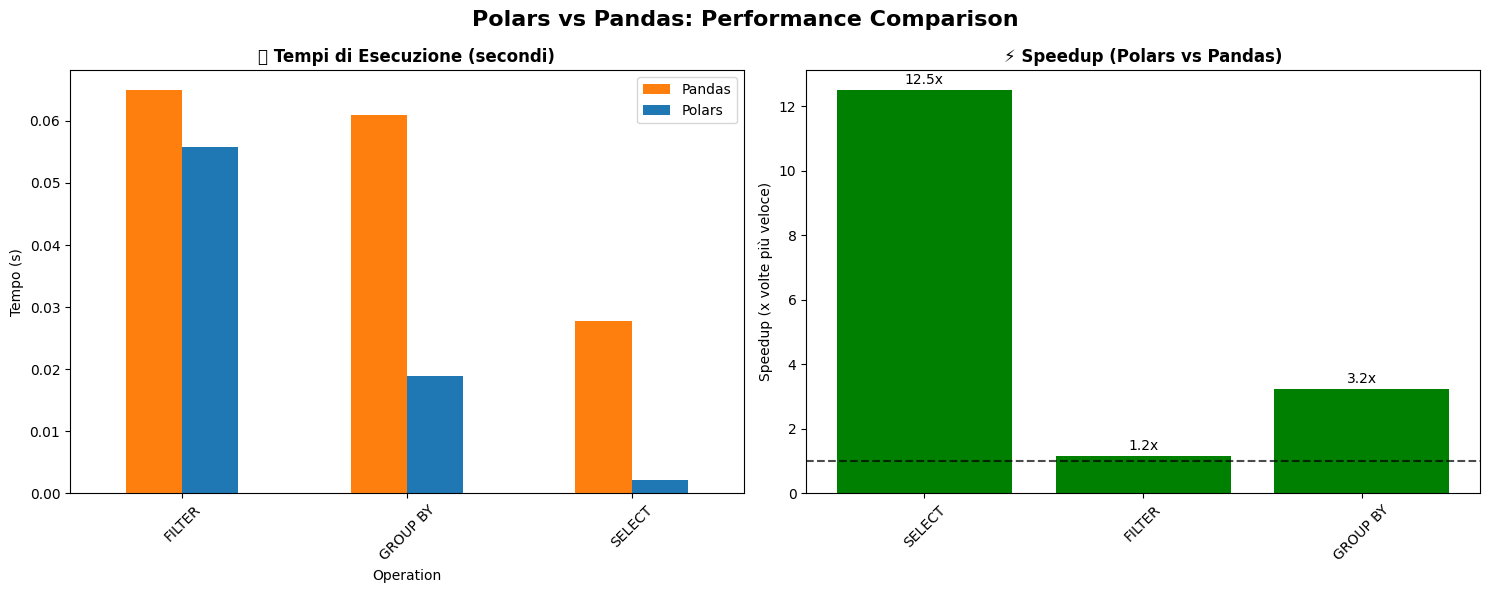

In [6]:
# Visualizzazioni Grafiche
if benchmark_results and len(benchmark_results) >= 2:
    print("\nVISUALIZZAZIONI GRAFICHE")
    print("="*50)
    
    try:
        # Configurazione dei grafici
        fig, axes = plt.subplots(1, 2, figsize=(15, 6))
        fig.suptitle('Polars vs Pandas: Performance Comparison', fontsize=16, fontweight='bold')
        
        # 1. Grafico tempi di esecuzione
        ax1 = axes[0]
        time_comparison = results_df.pivot_table(
            index='Operation',
            columns='Library',
            values='Time (seconds)',
            aggfunc='mean'
        )
        time_comparison.plot(kind='bar', ax=ax1, color=['#ff7f0e', '#1f77b4'])
        ax1.set_title('⏱ Tempi di Esecuzione (secondi)', fontweight='bold')
        ax1.set_ylabel('Tempo (s)')
        ax1.tick_params(axis='x', rotation=45)
        ax1.legend()
        
        # 2. Grafico speedup
        ax2 = axes[1]
        if 'speedup_df' in locals():
            bars = ax2.bar(speedup_df['Operation'], speedup_df['Speedup (x)'],
                           color=['green' if x > 1 else 'red' for x in speedup_df['Speedup (x)']])
            ax2.set_title('Speedup (Polars vs Pandas)', fontweight='bold')
            ax2.set_ylabel('Speedup (x volte più veloce)')
            ax2.tick_params(axis='x', rotation=45)
            ax2.axhline(y=1, color='black', linestyle='--', alpha=0.7)
            
            # Aggiungere valori sulle barre
            for bar, value in zip(bars, speedup_df['Speedup (x)']):
                height = bar.get_height()
                ax2.text(bar.get_x() + bar.get_width()/2., height + 0.1,
                        f'{value:.1f}x', ha='center', va='bottom', fontsize=10)
        
        plt.tight_layout()
        plt.show()
        
    except Exception as e:
        print(f"Errore nella creazione dei grafici: {e}")
        print("Assicurati che matplotlib sia installato correttamente")
else:
    print("\nGrafici non disponibili - dati insufficienti")


In [ ]:
# Informazioni aggiuntive
print("GUIDA RAPIDA BENCHMARK")
print("=" * 40)
print("Benchmark completato con successo!")
print("\nPer personalizzare:")
print(" • Modifica dataset_sizes per testare dimensioni diverse")
print(" • Aggiungi nuove operazioni nelle celle di test")
print(" • Cambia parametri di complessità in generate_test_data()")
print("\nInterpretazione risultati:")
print(" • Speedup > 1: Polars più veloce")
print(" • Speedup < 1: Pandas più veloce")
print(" • Memory (MB): uso memoria (+ = aumento, - = diminuzione)")
print("\nPer installare le dipendenze:")
print("pip install pandas polars numpy matplotlib seaborn psutil")
print("\nBuon benchmarking!")
